In [ ]:
import numpy as np
import pickle
import joblib

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Load dataset
data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train model
model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)

print("Model trained successfully!")
print("Accuracy:", accuracy_score(y_test, model.predict(X_test)))

# Save using Pickle
with open("model.pkl", "wb") as file:
    pickle.dump(model, file)

# Save using Joblib
joblib.dump(model, "model.joblib")

print("Model saved using Pickle and Joblib!")

Model trained successfully!
Accuracy: 0.956140350877193
Model saved using Pickle and Joblib!


In [ ]:
# Load Pickle model
with open("model.pkl", "rb") as file:
    pickle_model = pickle.load(file)

# Load Joblib model
joblib_model = joblib.load("model.joblib")

# Predict using loaded models
print("Pickle prediction:", pickle_model.predict(X_test[:5]))
print("Joblib prediction:", joblib_model.predict(X_test[:5]))

print("Models loaded successfully!")

Pickle prediction: [1 0 0 1 1]
Joblib prediction: [1 0 0 1 1]
Models loaded successfully!


In [ ]:
import numpy as np

def step_function(x):
    return np.where(x >= 0, 1, 0)

# AND gate inputs
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([0, 0, 0, 1])

# Manually chosen weights and bias
weights = np.array([1.0, 1.0])
bias = -1.5

for inputs, target in zip(X, y):
    z = np.dot(inputs, weights) + bias
    prediction = step_function(z)
    print(f"Input: {inputs}, Target: {target}, Prediction: {prediction}")

Input: [0 0], Target: 0, Prediction: 0
Input: [0 1], Target: 0, Prediction: 0
Input: [1 0], Target: 0, Prediction: 0
Input: [1 1], Target: 1, Prediction: 1


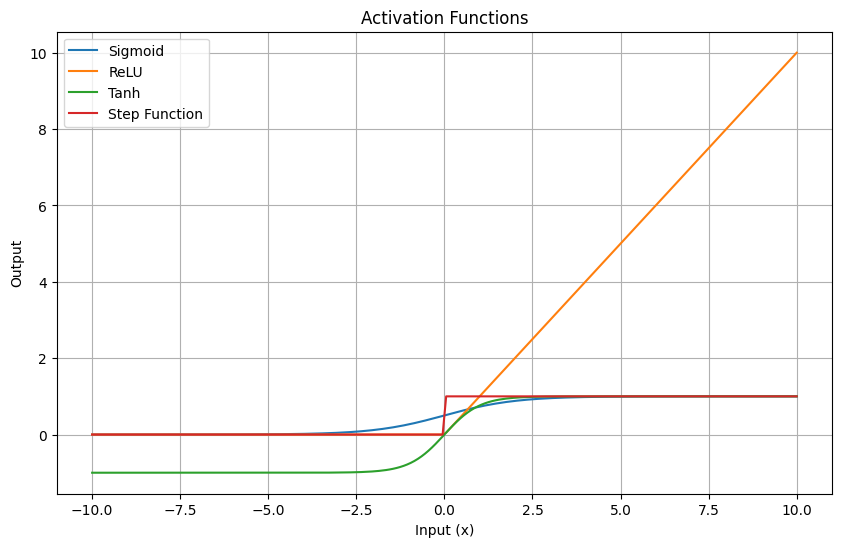

In [ ]:
# visualize active functions
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-10, 10, 200)

sigmoid = 1 / (1 + np.exp(-x))
relu = np.maximum(0, x)
tanh = np.tanh(x)
step = (x >= 0).astype(int)

plt.figure(figsize=(10, 6))
plt.plot(x, sigmoid, label="Sigmoid")
plt.plot(x, relu, label="ReLU")
plt.plot(x, tanh, label="Tanh")
plt.plot(x, step, label="Step Function")

plt.title("Activation Functions")
plt.xlabel("Input (x)")
plt.ylabel("Output")
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
import numpy as np

def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))

# Two inputs, two hidden neurons, one output neuron
X = np.array([[0.5, 0.8]])

W1 = np.array([
    [0.2, 0.4],
    [0.3, 0.5]
])
b1 = np.array([[0.1, 0.1]])

W2 = np.array([[0.6], [0.7]])
b2 = np.array([[0.2]])

# Forward propagation
Z1 = X @ W1 + b1
A1 = sigmoid(Z1)

Z2 = A1 @ W2 + b2
A2 = sigmoid(Z2)

print("Input:", X)
print("Hidden layer output:", A1)
print("Final prediction:", A2)

Input: [[0.5 0.8]]
Hidden layer output: [[0.60825903 0.66818777]]
Final prediction: [[0.73743647]]


In [ ]:
import numpy as np

y_true = np.array([1, 0, 1, 1])
y_pred = np.array([0.9, 0.2, 0.8, 0.7])

# Mean Squared Error
mse = np.mean((y_true - y_pred) ** 2)

# Binary Cross-Entropy
epsilon = 1e-7
p = np.clip(y_pred, epsilon, 1 - epsilon)

bce = -np.mean(
    y_true * np.log(p) +
    (1 - y_true) * np.log(1 - p)
)

print("Mean Squared Error:", mse)
print("Binary Cross-Entropy:", bce)

Mean Squared Error: 0.045
Binary Cross-Entropy: 0.22708064055624455


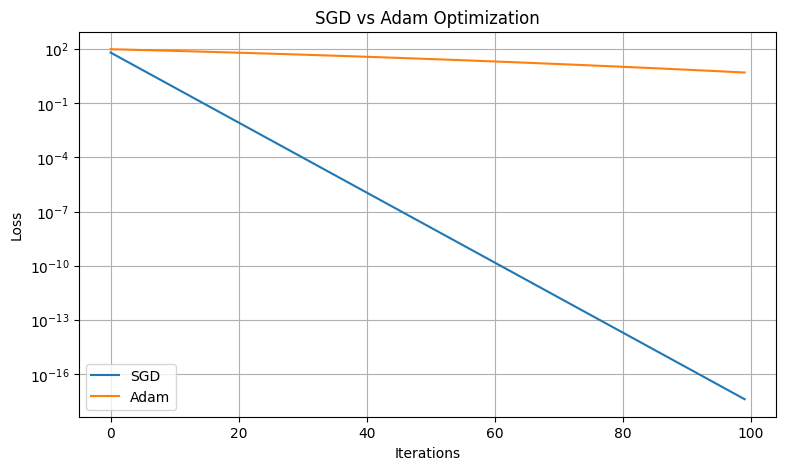

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def optimize(optimizer, learning_rate=0.1, steps=100):
    x = 10.0
    m = 0.0
    v = 0.0
    beta1 = 0.9
    beta2 = 0.999
    epsilon = 1e-8
    losses = []

    for t in range(1, steps + 1):
        # Function: f(x) = x^2
        gradient = 2 * x

        if optimizer == "SGD":
            x = x - learning_rate * gradient

        elif optimizer == "Adam":
            m = beta1 * m + (1 - beta1) * gradient
            v = beta2 * v + (1 - beta2) * gradient ** 2

            m_hat = m / (1 - beta1 ** t)
            v_hat = v / (1 - beta2 ** t)

            x = x - learning_rate * m_hat / (np.sqrt(v_hat) + epsilon)

        losses.append(x ** 2)

    return losses

plt.figure(figsize=(9, 5))
plt.plot(optimize("SGD"), label="SGD")
plt.plot(optimize("Adam"), label="Adam")

plt.title("SGD vs Adam Optimization")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.yscale("log")
plt.legend()
plt.grid(True)
plt.show()

Epoch 200, Loss: 0.1548
Epoch 400, Loss: 0.0880
Epoch 600, Loss: 0.0740
Epoch 800, Loss: 0.0652
Epoch 1000, Loss: 0.0621
Epoch 1200, Loss: 0.0609
Epoch 1400, Loss: 0.0601
Epoch 1600, Loss: 0.0594
Epoch 1800, Loss: 0.0590
Epoch 2000, Loss: 0.0585

Training completed!
Test Accuracy: 99.0 %


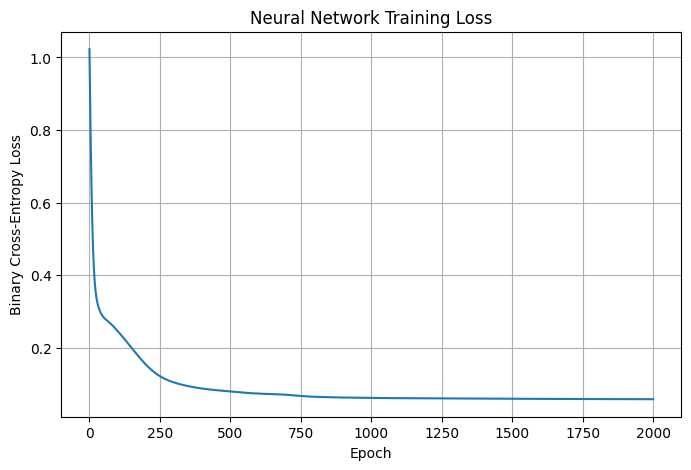

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Generate dataset
X, y = make_moons(
    n_samples=1000,
    noise=0.2,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y.reshape(-1, 1),
    test_size=0.2,
    random_state=42
)

# Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Activation functions
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def relu(z):
    return np.maximum(0, z)

# Initialize weights
np.random.seed(42)

input_size = 2
hidden_size = 16
output_size = 1

W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2 / input_size)
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * np.sqrt(1 / hidden_size)
b2 = np.zeros((1, output_size))

# Adam parameters
learning_rate = 0.01
beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8

parameters = [W1, b1, W2, b2]
m = [np.zeros_like(p) for p in parameters]
v = [np.zeros_like(p) for p in parameters]

epochs = 2000
losses = []
optimizer = "Adam"  # Change to "SGD" to use SGD

# Training loop
for epoch in range(1, epochs + 1):

    # Forward propagation
    Z1 = X_train @ W1 + b1
    A1 = relu(Z1)

    Z2 = A1 @ W2 + b2
    A2 = sigmoid(Z2)

    # Binary cross-entropy loss
    p = np.clip(A2, 1e-8, 1 - 1e-8)
    loss = -np.mean(
        y_train * np.log(p) +
        (1 - y_train) * np.log(1 - p)
    )
    losses.append(loss)

    # Backpropagation
    n = len(X_train)

    dZ2 = (A2 - y_train) / n
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * (Z1 > 0)

    dW1 = X_train.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    gradients = [dW1, db1, dW2, db2]

    # Update parameters
    for i in range(len(parameters)):
        if optimizer == "SGD":
            parameters[i] -= learning_rate * gradients[i]

        elif optimizer == "Adam":
            m[i] = beta1 * m[i] + (1 - beta1) * gradients[i]
            v[i] = beta2 * v[i] + (1 - beta2) * gradients[i] ** 2

            m_hat = m[i] / (1 - beta1 ** epoch)
            v_hat = v[i] / (1 - beta2 ** epoch)

            parameters[i] -= (
                learning_rate * m_hat /
                (np.sqrt(v_hat) + epsilon)
            )

    if epoch % 200 == 0:
        print(f"Epoch {epoch}, Loss: {loss:.4f}")

# Evaluate model
W1, b1, W2, b2 = parameters

Z1 = X_test @ W1 + b1
A1 = relu(Z1)
Z2 = A1 @ W2 + b2
predictions = (sigmoid(Z2) >= 0.5).astype(int)

accuracy = accuracy_score(y_test, predictions)

print("\nTraining completed!")
print("Test Accuracy:", round(accuracy * 100, 2), "%")

# Plot loss
plt.figure(figsize=(8, 5))
plt.plot(losses)
plt.title("Neural Network Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.grid(True)
plt.show()

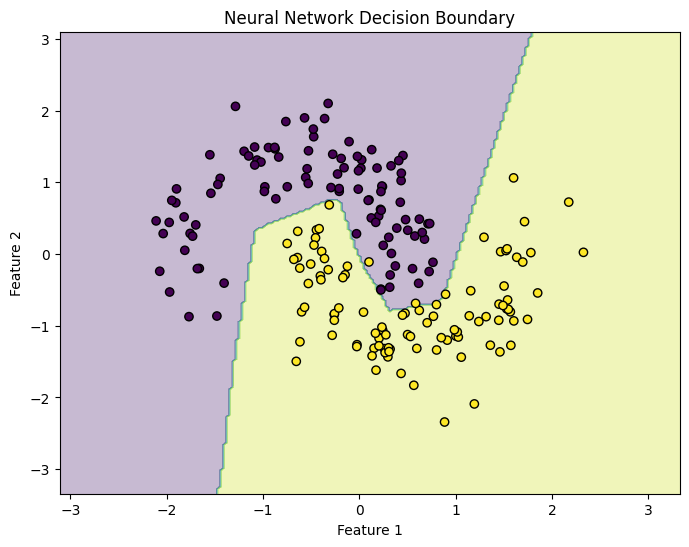

In [ ]:
xx, yy = np.meshgrid(
    np.linspace(X_test[:, 0].min() - 1, X_test[:, 0].max() + 1, 200),
    np.linspace(X_test[:, 1].min() - 1, X_test[:, 1].max() + 1, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]

Z1 = grid @ W1 + b1
A1 = relu(Z1)
Z2 = A1 @ W2 + b2

Z = (sigmoid(Z2) >= 0.5).astype(int).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3)
plt.scatter(
    X_test[:, 0], X_test[:, 1],
    c=y_test.ravel(), edgecolors="black"
)

plt.title("Neural Network Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()